<a href="https://colab.research.google.com/github/eparrama/proyecto_7/blob/main/S7_Version_Estudiante_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajaremos con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users_latam.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

**Explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.


---
## 🧩 Paso 1: Cargar y explorar

**Familiarizarse con la estructura de los tres datasets**.  
Validar que los archivos se carguen correctamente, conocer sus columnas y tipos de datos, y detectar posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

- Importar las librerías necesarias
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guardar los DataFrames en las variables: `plans`, `users`, `usage`.  
- Mostrar las primeras filas de cada DataFrame usando `.head()`.


In [3]:
# importar librerías
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# cargar archivos
plans = pd.read_csv('/content/plans.csv')
users = pd.read_csv('/content/users_latam.csv')
usage = pd.read_csv('/content/usage.csv')

In [5]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [6]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [7]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

- Revisar el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usar `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [8]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [9]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 260.0+ bytes


In [10]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [11]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

- Contar valores nulos por columna para cada dataset.
- Calcular la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.



In [12]:
# cantidad de nulos para users
print("Cantidad de Nulos por Columna para el Data Set users:")
print(users.isna().sum())
print("Proporción de Nulos por Columna para el Data Set users:")
print(users.isna().mean()*100)

Cantidad de Nulos por Columna para el Data Set users:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
Proporción de Nulos por Columna para el Data Set users:
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [13]:
# cantidad de nulos para usage
print("Cantidad de Nulos por Columna para el Data Set usage:")
print(usage.isna().sum())
print("Proporción de Nulos por Columna para el Data Set usage:")
print(usage.isna().mean()*100)

Cantidad de Nulos por Columna para el Data Set usage:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
Proporción de Nulos por Columna para el Data Set usage:
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64



## **Nota:**
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.
 ---

**Valores nulos**  
- Columnas con valores faltantes y su proporción  
  
  **Diagnóstico**
- En el Data Set **users** la columna "**churn_date**" hay un **88.3%** de nulos pero esto se debe a que es la fecha de cancelación por lo que se asume que dichos nulos corresponden a usuarios activos que no han cancelado el servicio por lo tanto se **ignoran**
- En **city** tenemos el **11.7%** de nulos (469) por lo que investigaremos qué sucede con dicha columna
- Para el Data Set de **usage** hay lo siguiente:
- "**date**" tiene el **0.125%** de nulos por lo bajo que es, se **ignora** y deja como nulos
- "**duration**" tiene el **55.2%** de nulos por lo que se investigará e **imputará** con la media o la mediana en caso de ser necesario
- "**length**" tiene el **44.7%** de nulos por lo que se investigará e **imputará** con la media o la mediana en caso de ser necesario

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

- Explorar las columnas numéricas con **un resumen estadístico** y describir brevemente los hallazgos.
- Explorar las columnas categóricas **relevantes**, revisar sus valores únicos y describir brevemente los hallazgos.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [14]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` empieza a partir del número 10,000 y tiene 4,000 registros, su media y mediana son iguales, por lo que no hay nada que hacer pues su estadística es normal
- La columna `age` La edad media de los usuarios es de 33.7 años mientras que la mediana es 47, hay valores atípicos como el mínimo de -999 por lo que hay que investigar e imputar de ser necesario,

In [15]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- **Columnas `id` y `user_id`**, los valores estadísticos de **'id'** son congruentes pues tiene 40,000 registros y la media es 20,000 y coincide con la mediana; en el caso de **'user_id'** el conteo empieza en los 10,000 y tiene un máximo de 13,999 por lo que son 4,000 registros donde la media es normal y está muy cerca de la mediana, y no hay nada atípico.
- Las columnas **'duration' y 'length'** tienen registros en 0 y valores máximos muy altos que seguramente mueven la desviación std que es muy alta con respecto a la media, y en ambos casos la media es mayor a la mediana, hay que profundizar en el análisis, sobre todo de los máximos, pues el 0 podría equivaler a una llamada que terminó por algún motivo lo cual es viable

In [16]:
# explorar columnas categóricas de users
# with pd.option_context('display.max_rows', None) : #En caso de requerir ver todas las diferentes ciudades

columnas_user = ['city', 'plan']
for col in columnas_user :
    print(users[col].value_counts())

city
Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: count, dtype: int64
plan
Basico     2595
Premium    1405
Name: count, dtype: int64


- La columna `city` tiene **6 ciudades** diferentes y **96** registros que tienen valores desconocidos
- La columna `plan` consta de 2 tarifas: **Basico con 2,595 suscriptores y la Premium con 1,405**, no hay nulos ni desconocidos

In [17]:
# explorar columna categórica de usage
columnas_usage = ['type']
usage['type'].value_counts()

,count
type,
text,22092
call,17908


- La columna `type` nos muestra que **22,092 fueron mensajes de texto** mientras que **17,908 fueron llamadas** y no hay valores nulos o inválidos

---
**Valores inválidos o sentinels**  
- **Se encontraron valores inválidos (?) en la columna city y en age (-999)**
- **Corregir/borrar los inválidos e imputar los negativos**

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

- Convertir las columnas de fecha a tipo fecha y asegurar que el código sea a prueba de errores.  
- Revisar cuántas veces aparece cada año.
- Identificar fechas imposibles (ej. años futuros o negativos).



In [18]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], format='%Y-%m-%d %H:%M:%S.%f', errors='coerce')


In [19]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'],format='%Y-%m-%d %H:%M:%S.%f', errors='coerce')

In [20]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts()

,count
reg_date,
2024,1330
2023,1316
2022,1314
2026,40


**En `reg_date`, tenemos 4 diferentes fechas de las cuales 40 corresponden al 2026 que queda fuera del scope de nuestro análisis**

In [21]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts()

,count
date,
2024.0,39950


**En `date`, hay 39,950 registros con año 2024, de los cuales 50 son nulos como ya se había mencionado**  
Basaremos el análisis en estas fechas.

**Fechas fuera de rango**  
- Tenemos **40 fechas fuera de rango** en el **reg_date del dataset users** correspondientes al 2026, y hay **50 nulos en date de usage**
- **En el caso de reg_date de users eliminar los registros correspondientes al 2026**, el resto se mantiene. **En el caso de date de usage se quedan así por ser un porcentaje muy bajo 0.125%**

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

- En `age` se reemplaza el sentinel **-999** con la mediana.
- En `city` se reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marcar como nulas (`pd.NA`) las fechas fuera de rango.

In [22]:
# Reemplazar -999 por la mediana de age
age_mediana = users[users['age'] != -999]['age'].median()
users['age'] = users['age'].replace(-999,age_mediana)
# Verificar cambios
users['age'].describe()

,age
count,4000.000000
mean,48.136000
std,17.689919
min,18.000000
25%,33.000000
50%,48.000000
75%,63.000000
max,79.000000


In [23]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?',pd.NA)
# Verificar cambios
users['city'].describe()

,city
count,3435
unique,6
top,Bogotá
freq,808


In [24]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'] = users['reg_date'].mask(users['reg_date'].dt.year > 2024, pd.NaT)
# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False))

reg_date
2024.0    1330
2023.0    1316
2022.0    1314
NaN         40
Name: count, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

- Verificar si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  


In [25]:
# Verificación MAR en usage (Missing At Random) para duration
missing_duration_by_type = usage['duration'].isna().groupby(usage['type']).mean()
print(missing_duration_by_type)

type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [26]:
# Verificación MAR en usage (Missing At Random) para length
missing_length_by_type = usage['length'].isna().groupby(usage['type']).mean()
print(missing_length_by_type)

type
call    0.99933
text    0.00000
Name: length, dtype: float64


**Diagnóstico de nulos en `duration` y `length`**  

Ambas columnas están estrechamente vinculadas con la variable **‘type’**’. Un mensaje de texto carece de duración y una llamada no posee longitud de caracteres; por lo tanto, no se trata de datos faltantes (missingness), sino de valores que no aplican para la categoría. Se considera estos registros como **MNAR (Faltantes No Aleatorios)**, e imputarlos sería un error metodológico, ya que distorsionaría la estadística de dichas columnas. En consecuencia, se mantendrán como nulos.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

1. Construir una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombrar las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`

3. Combinar esta tabla con `users`.

In [27]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer total de llamadas
usage["call_mins"] = (usage["duration"]).astype(float) #conocer total de minutos

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg(
    {'is_text':sum,'is_call':sum,'call_mins':sum}).reset_index()

# observar resultado
usage_agg.head(3)

/tmp/ipykernel_2184/3760398454.py:7: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  usage_agg = usage.groupby('user_id').agg(


,user_id,is_text,is_call,call_mins
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:
# Renombrar columnas
usage_agg = usage_agg.rename(
    columns={'is_text' : 'cant_mensajes','is_call' : 'cant_llamadas','call_mins' : 'cant_minutos_llamada'})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [29]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users, usage_agg, on=['user_id'], how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

1. Para las columnas **numéricas** relevantes, obtener un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisar la distribución en **porcentajes** de cada categoría.

In [30]:
# Resumen estadístico de las columnas numéricas
user_profile['age'].describe()

,age
count,4000.000000
mean,48.136000
std,17.689919
min,18.000000
25%,33.000000
50%,48.000000
75%,63.000000
max,79.000000


In [31]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)*100

,proportion
plan,
Basico,64.875
Premium,35.125


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

Se grafican **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Para cada histograma:
- Se utiliza `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Se utiliza `palette=['skyblue','green']` y  se agregan títulos y etiquetas

In [32]:
user_profile['plan'].value_counts()

,count
plan,
Basico,2595
Premium,1405


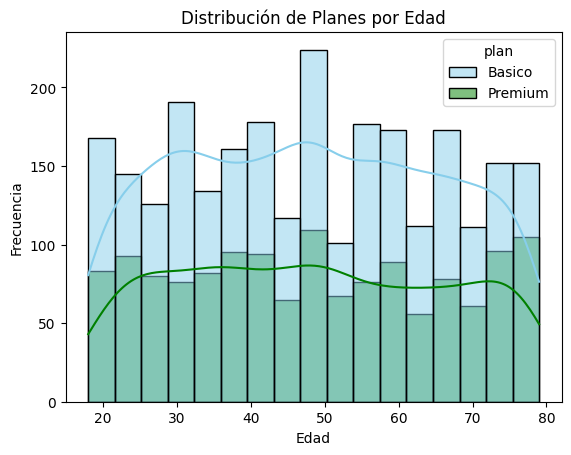

In [33]:
# Histograma para visualizar la edad (age)

sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue','green'], kde=True)
plt.title('Distribución de Planes por Edad')
plt.ylabel('Frecuencia')
plt.xlabel('Edad')
# plt.xticks(range(18, 81, 10))
plt.show()

💡Insights: **Distribución de Planes por Edad**
- Los usuarios utilizan ambos planes independientemente de la edad. Donde hay más usuarios en ambos planes es en el rango de **47 a 51 años** y de ahí observamos una marcada preferencia por el plan **Premium** en el rango de **77 a 79 años** y de **29 a 32** prefieren el plan **Básico**
- Es una **distribución uniforme y simétrica**, no hay un sesgo relevante


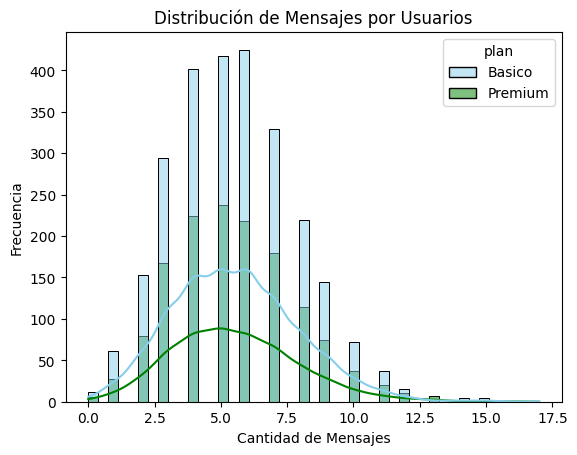

In [34]:
# Histograma para visualizar la cant_mensajes

sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue','green'], kde=True)
plt.title('Distribución de Mensajes por Usuarios')
plt.ylabel('Frecuencia')
plt.xlabel('Cantidad de Mensajes')
plt.show()


💡Insights:

- La mayoría de los usuarios envía de **4 a 6 mensajes de texto**
- La distribución es simétrica con sesgo a la derecha (**right skewed**), tal vez sea necesario revisar los valores extremos hacia arriba para detectar outliers


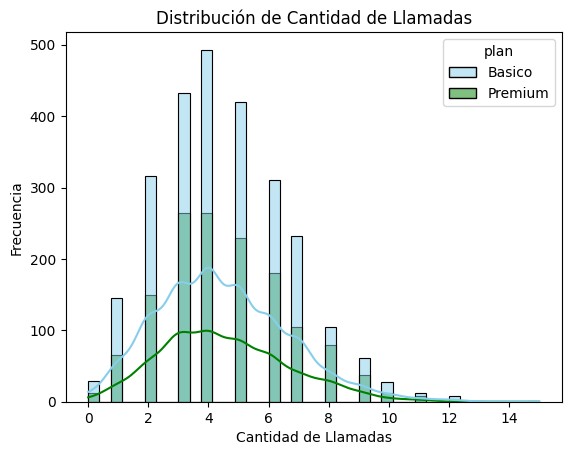

In [35]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue','green'], kde=True)
plt.title('Distribución de Cantidad de Llamadas')
plt.ylabel('Frecuencia')
plt.xlabel('Cantidad de Llamadas')
plt.show()

💡Insights:

- La mayoría de los usuarios hace de **3 a 5 llamadas**
- La distribución tiene sesgo a la derecha (**right skewed**), es necesario revisar los valores extremos para detectar outliers


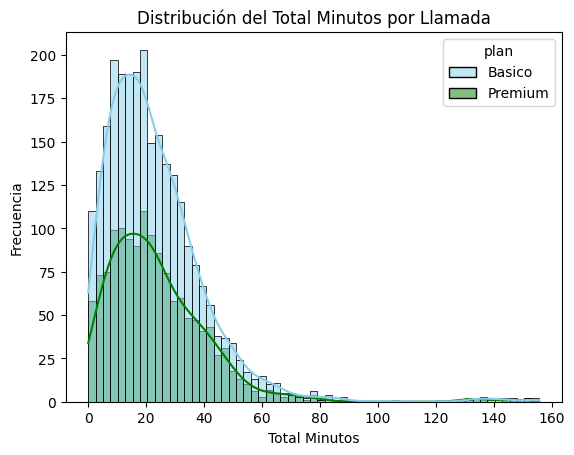

In [36]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue','green'], kde=True)
plt.title('Distribución del Total Minutos por Llamada')
plt.ylabel('Frecuencia')
plt.xlabel('Total Minutos')
plt.show()

💡Insights:
- La mayor duración de las llamadas está entre **7.5 y 20 minutos**
- La distribución tiene sesgo a la derecha (**right skewed**) muy marcado por lo que se requiere verificar los valores máximos para detectar outliers

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

- Se utilizan **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Se crea **for** para generar los 4 boxplots automáticamente.
- Se crea otro bucle para calcular los límites de esas columnas usando el **método IQR**
- Solamente hay outliers de un solo lado, por lo que no es necesario calcular ambos límites.

- Dentro del bucle, se usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

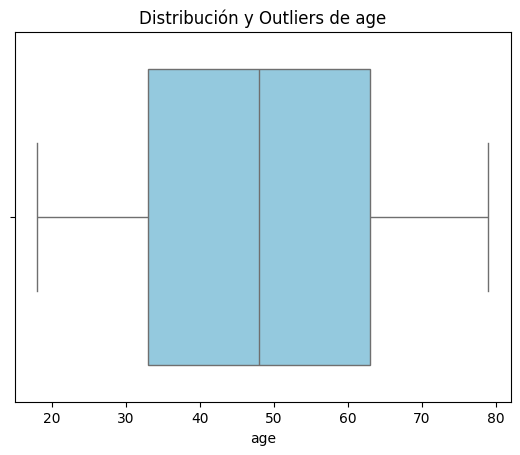

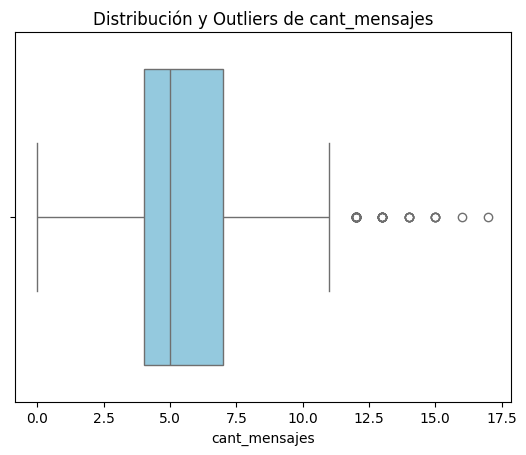

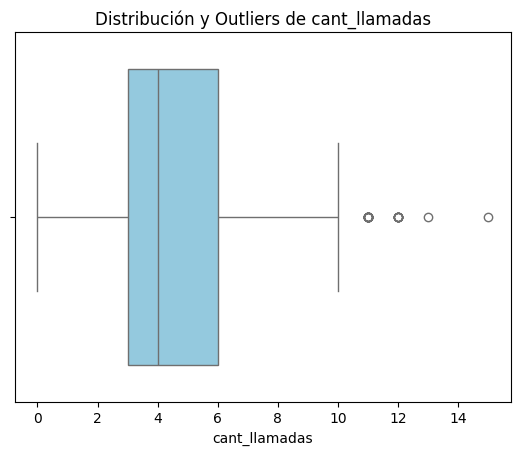

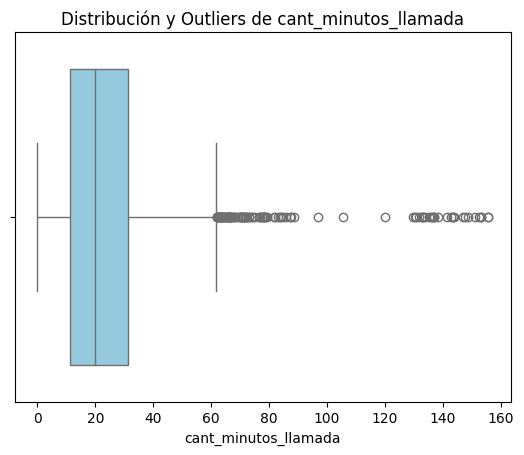

In [46]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas :
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Distribución y Outliers de {col}')
    plt.xlabel(col)
    plt.show()

💡Insights:
- **Age: No presenta outliers** por lo que no hay que hacer nada sobre esta columna
- **cant_mensajes: Presenta outliers** por lo que hay que proceder a **revisar**
- **cant_llamadas: Presenta outliers** por lo que hay que proceder a **revisar**
- **cant_minutos_llamada: Presenta outliers** por lo que hay que proceder a **revisar**

In [38]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes','cant_llamadas','cant_minutos_llamada']
for col in columnas_limites :
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    ExSup = Q3 + 1.5*IQR
    print("IQR para", col ,IQR, "Límite Superior", ExSup)

IQR para cant_mensajes 3.0 Límite Superior 11.5
IQR para cant_llamadas 3.0 Límite Superior 10.5
IQR para cant_minutos_llamada 20.295 Límite Superior 61.8575


In [39]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


### 💡Insights:
- **cant_mensajes**: aunque el máximo de mensajes está por arriba del límite superior calculado considero que se deben de **mantener los outliers** porque la desviación estándar no se ve afectada por dichos outliers y el diferencial entre la media y la mediana es mínimo (5.5 vs 5.0), además de que en la vida real dichos valores son posibles
- **cant_llamadas**: De la misma forma y por los mismos motivos considero que se deben de **conservar los outliers**, la mediana tiene valor de 4.0 vs 4.4 de la media
- **cant_minutos_llamada**: Aunque aquí sí hay un mayor diferencial entre la media (23.31) y la mediana (19.78) ya que la media es "jalada" hacia arriba por los valores altos, aún se mantienen en rangos lógicos, creo que son valores reales de negocio, por lo tanto habría que **conservar los valores extremos**

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

- Se crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Se utilizan comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [40]:
# Crear columna grupo_uso

user_profile["grupo_uso"] = np.where(
            (user_profile["cant_llamadas"] < 5) &
            (user_profile["cant_mensajes"] < 5), "Bajo uso",
            np.where((user_profile["cant_llamadas"] < 10)
                 & (user_profile["cant_mensajes"] < 10), "Uso medio",
                 "Alto uso"), )


In [41]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

- Se crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Se utilizan comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [42]:
# Crear columna grupo_edad
user_profile["grupo_edad"] = np.where(
            user_profile["age"] < 30, "Joven",
            np.where(user_profile["age"] < 60, "Adulto", "Adulto Mayor"), )


In [43]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

- Se crean dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Se agrega título y etiquetas a los ejes en cada gráfico.

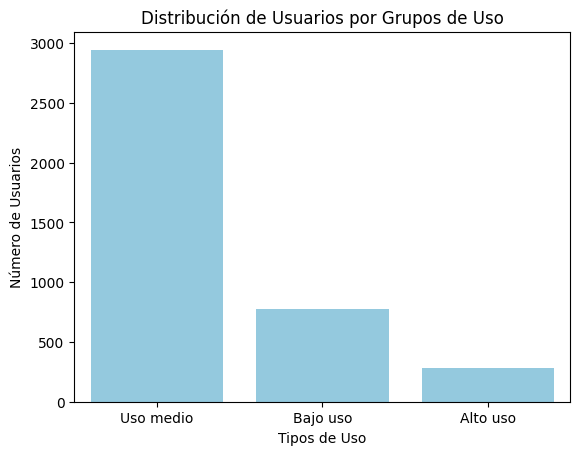

In [44]:
# Visualización de los segmentos por uso

sns.countplot(data=user_profile, x="grupo_uso", color='skyblue',order=user_profile[
        "grupo_uso"].value_counts().index)
plt.title("Distribución de Usuarios por Grupos de Uso")
plt.xlabel("Tipos de Uso")
plt.ylabel("Número de Usuarios")
plt.show()


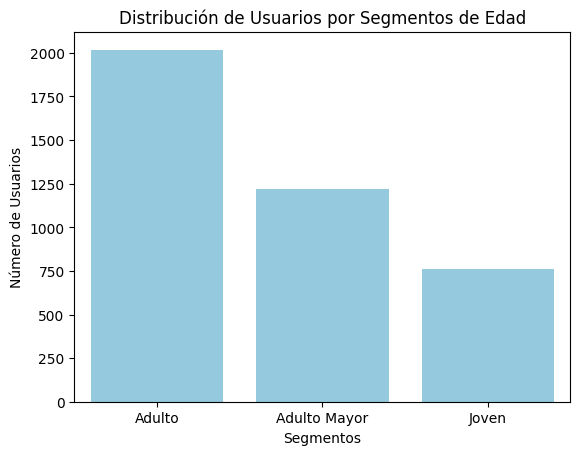

In [45]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x="grupo_edad", color='skyblue',order=user_profile[
        "grupo_edad"].value_counts().index)
plt.title("Distribución de Usuarios por Segmentos de Edad")
plt.xlabel("Segmentos")
plt.ylabel("Número de Usuarios")
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes existen y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) hay y qué implican para el negocio?


- ¿Qué recomendaciones se harían para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?


### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- En el data set **users** la columna **city** tiene un **11.73%** de nulos y **churn_date** tiene un **88.35% de nulos** pero esto se debe a que como es la **fecha de cancelación** se asume que dichos nulos **corresponden a usuarios activos** que no han cancelado el servicio. La columna **age** presentaba valores inválidos que fueron descartados, así como la columna **city** donde encontramos valores desconocidos que también fueron descartados. En **reg_date** 40 fechas  corresponden al 2026 por lo que fueron descartadas del análisis
- En el data set de **usage** la columna **"duration"** tiene el **55.2% de nulos**, pero se debe a que corresponde a mensajes de texto que no consumen minutos y **"length"** tiene el **44.7% de nulos**, se debe a que corresponde a llamadas que no tienen longitud por lo que se dejan intactas
- **"date"** tiene el **0.125%** de nulos por lo bajo que es, se ignora y deja como nulos
- Para **cantidad de mensajes, cantidad de llamadas y cantidad de minutos por llamada** hay valores que pueden considerarse como outliers por estar estadísticamente fuera del rango más alto pero desde la lógica del negocio son valores que se pueden presentar dada la naturaleza de los campos

🔍 **Segmentos por Edad**
- El segmento con mayor cantidad de usuarios es el **adulto con edades entre 31 y 59 años** seguido del segmento de adultos mayores y el que **menos usuarios** tiene es el segmento de **jóvenes menores de 30 años**

📊 **Segmentos por Nivel de Uso**
- La **mayoría** de los usuarios tienen un nivel de **Uso Medio** seguido por los usuarios de  de **Bajo Uso y muy pocos de Alto Uso**

➡️ Esto sugiere que:
- El segmento de jóvenes es un mercado potencial que podría crecer ya que al parecer no está siendo bien atendido
- Los usuarios del segmento de uso medio están contentos con el plan tarifario que tienen pero representan una oportunidad de negocio para **ConnectaTel**

💡 **Recomendaciones**
- Se deberán implementar y promover planes más atractivos para captar más usuarios del segmento de jóvenes
- Hacer campañas en medios digitales en donde los jóvenes tienen más acceso y puedan contratar más fácilmente los planes y productos
- Diseñar programas de fidelidad y retención de usuarios para el segmento más grande que es el de adultos, así como atención personalizada
- Para el segmento de adultos mayores, diseñar también programas de lealtad y mejorar la experiencia de uso de los dispositivos, la adquisición de planes, etc.
- Diseñar e implementar una estrategia para promover planes más atractivos para que los usuarios del segmento de uso medio pasen a uso alto en donde se pueda cobrar más por dichos planes
- Analizar si el segmento de bajo uso puede caer en la pérdida de usuarios y de ser así analizar la posibilidad de crear planes alternativos que ayuden a retener a dichos clientes y por qué no a subir de nivel al medio